# Forecasting tomorrow's air pollution in ten major cities

**Question.** How polluted is the air in ten of the largest cities of Africa, Asia and Latin America, and can tomorrow's fine particle pollution be forecast well enough to warn people a day ahead?

**Why it matters.** Fine particulate matter (PM2.5) is the pollutant that does the most damage to human health. The World Health Organization attributes several million premature deaths a year to outdoor air pollution, most of them in low and middle income countries. The WHO guideline is an annual average of 5 micrograms per cubic metre and a 24-hour average of 15. Many of the world's fastest growing cities exceed those levels many times over, and most have few ground monitors. A reliable next-day forecast lets schools, hospitals and people with asthma or heart disease plan around the worst days.

**Data.** Two open sources, both accessed through the [Open-Meteo](https://open-meteo.com/) API with no key required:

* **PM2.5**: the Copernicus Atmosphere Monitoring Service (CAMS) global analysis, hourly since August 2022. CAMS combines satellite observations with an atmospheric chemistry model on a grid of roughly 40 km.
* **Weather**: the ERA5 reanalysis from the European Centre for Medium-Range Weather Forecasts (temperature, rain, wind, humidity).

An important caveat up front: CAMS is a **modelled estimate constrained by satellites, not a ground measurement**. It represents the average over a large grid cell, so it is smoother than a roadside monitor and can be biased in places with few observations. It is used here because it is consistent across cities that have little or no public monitoring.

**What this notebook does**

1. Downloads four years of hourly PM2.5 and daily weather for ten cities
2. Compares each city with the WHO guidelines and describes seasonality
3. Builds a next-day forecasting model and tests it on the most recent 12 months against simple baselines
4. Evaluates the model as a warning system for high pollution days
5. Exports the model so the dashboard can produce a live forecast in the browser

## 1. Setup

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xgboost as xgb
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path("..")
RAW = ROOT / "data" / "raw"
APP = ROOT / "docs" / "data"
RAW.mkdir(parents=True, exist_ok=True)
APP.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#77766f"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e9e8e3", "axes.axisbelow": True, "font.size": 10,
})

CITIES = {
    "Lagos": (6.45, 3.39, "Nigeria"),
    "Accra": (5.56, -0.20, "Ghana"),
    "Kinshasa": (-4.32, 15.31, "DR Congo"),
    "Nairobi": (-1.29, 36.82, "Kenya"),
    "Cairo": (30.04, 31.24, "Egypt"),
    "Delhi": (28.61, 77.21, "India"),
    "Lahore": (31.55, 74.34, "Pakistan"),
    "Dhaka": (23.81, 90.41, "Bangladesh"),
    "Jakarta": (-6.21, 106.85, "Indonesia"),
    "Mexico City": (19.43, -99.13, "Mexico"),
}
START, END = "2022-08-05", "2026-11-12"
WHO_ANNUAL, WHO_DAILY = 5, 15

## 2. Download the data

One request per city for hourly PM2.5 and one for daily weather. Times are returned in each city's local time zone, so a "day" means a local calendar day. Files are cached so the notebook can be rerun without calling the API again.

In [2]:
def get_json(url, params):
    for attempt in range(5):
        try:
            response = requests.get(url, params=params, timeout=120)
            response.raise_for_status()
            return response.json()
        except requests.RequestException:
            if attempt == 4:
                raise
            time.sleep(3 * (attempt + 1))


def load_city(name):
    lat, lon, _ = CITIES[name]
    slug = name.lower().replace(" ", "_")
    pm_path, wx_path = RAW / f"pm25_{slug}.csv", RAW / f"weather_{slug}.csv"
    if not pm_path.exists():
        data = get_json("https://air-quality-api.open-meteo.com/v1/air-quality",
                        {"latitude": lat, "longitude": lon, "hourly": "pm2_5", "start_date": START, "end_date": END, "timezone": "auto"})
        pd.DataFrame(data["hourly"]).to_csv(pm_path, index=False)
    if not wx_path.exists():
        data = get_json("https://archive-api.open-meteo.com/v1/archive",
                        {"latitude": lat, "longitude": lon, "start_date": START, "end_date": END, "timezone": "auto",
                         "daily": "temperature_2m_mean,precipitation_sum,wind_speed_10m_mean,relative_humidity_2m_mean"})
        pd.DataFrame(data["daily"]).to_csv(wx_path, index=False)
    hourly = pd.read_csv(pm_path, parse_dates=["time"])
    hourly["date"] = hourly["time"].dt.normalize()
    daily = hourly.groupby("date")["pm2_5"].agg(pm25="mean", hours="count")
    daily.loc[daily["hours"] < 18, "pm25"] = np.nan
    weather = pd.read_csv(wx_path, parse_dates=["time"]).set_index("time")
    weather.columns = ["temp", "rain", "wind", "humidity"]
    out = daily[["pm25"]].join(weather)
    out["city"] = name
    return out.reset_index(), hourly


frames, hourly_frames = [], {}
for city in CITIES:
    daily_city, hourly_city = load_city(city)
    frames.append(daily_city)
    hourly_frames[city] = hourly_city
data = pd.concat(frames, ignore_index=True)
print(f"{len(data):,} city-days, {data['date'].min():%d %b %Y} to {data['date'].max():%d %b %Y}")
print(f"Hourly PM2.5 values: {sum(len(h) for h in hourly_frames.values()):,}.  Days without a valid daily mean: {data['pm25'].isna().mean():.2%}")
data.head(3)

15,610 city-days, 05 Aug 2022 to 12 Nov 2026
Hourly PM2.5 values: 374,640.  Days without a valid daily mean: 0.00%


,date,pm25,temp,rain,wind,humidity,city
0,2022-08-05,17.554167,24.8,0.5,14.1,81,Lagos
1,2022-08-06,17.995833,24.9,0.9,14.6,82,Lagos
2,2022-08-07,18.291667,25.1,0.3,15.4,82,Lagos


## 3. How polluted are these cities?

### Against the WHO guidelines

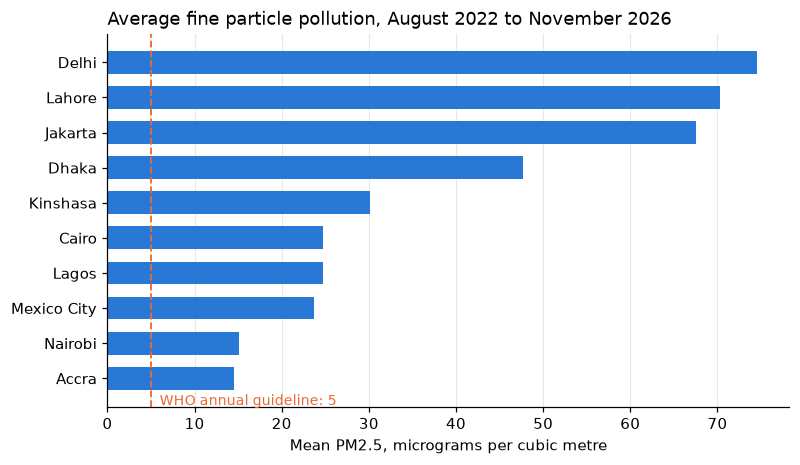

,mean_pm25,median_pm25,p95,days_above_guideline,days_above_75,times_who_annual
city,,,,,,
Delhi,74.53,65.70,148.42,1.00,0.40,14.91
Lahore,70.27,57.01,160.58,1.00,0.32,14.05
Jakarta,67.53,68.52,108.01,0.99,0.40,13.51
Dhaka,47.71,42.69,98.98,0.88,0.17,9.54
Kinshasa,30.12,27.61,57.33,0.91,0.01,6.02
Cairo,24.72,22.55,41.61,0.95,0.00,4.94
Lagos,24.69,19.11,61.25,0.76,0.03,4.94
Mexico City,23.75,23.22,39.87,0.82,0.00,4.75
Nairobi,15.09,13.33,27.78,0.41,0.00,3.02


In [3]:
stats = data.groupby("city").agg(
    mean_pm25=("pm25", "mean"),
    median_pm25=("pm25", "median"),
    p95=("pm25", lambda s: s.quantile(0.95)),
    days_above_guideline=("pm25", lambda s: (s > WHO_DAILY).mean()),
    days_above_75=("pm25", lambda s: (s > 75).mean()),
).sort_values("mean_pm25", ascending=False)
stats["times_who_annual"] = stats["mean_pm25"] / WHO_ANNUAL

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(stats.index[::-1], stats["mean_pm25"][::-1], color=BLUE, height=0.65)
ax.axvline(WHO_ANNUAL, color=ORANGE, ls="--", lw=1.2)
ax.text(WHO_ANNUAL + 1, -0.45, "WHO annual guideline: 5", color=ORANGE, fontsize=9, va="top")
ax.set_xlabel("Mean PM2.5, micrograms per cubic metre")
ax.set_title("Average fine particle pollution, August 2022 to November 2026", loc="left")
ax.grid(axis="y", visible=False)
plt.show()
stats.round(2)

Every one of the ten cities is above the WHO annual guideline, and the most polluted are above it many times over. `days_above_guideline` is the share of days on which the 24-hour average exceeded 15, and `days_above_75` is the share of days above 75, the level the WHO describes as its least demanding interim target.

### Seasonality

Pollution is strongly seasonal, and the season differs by region.

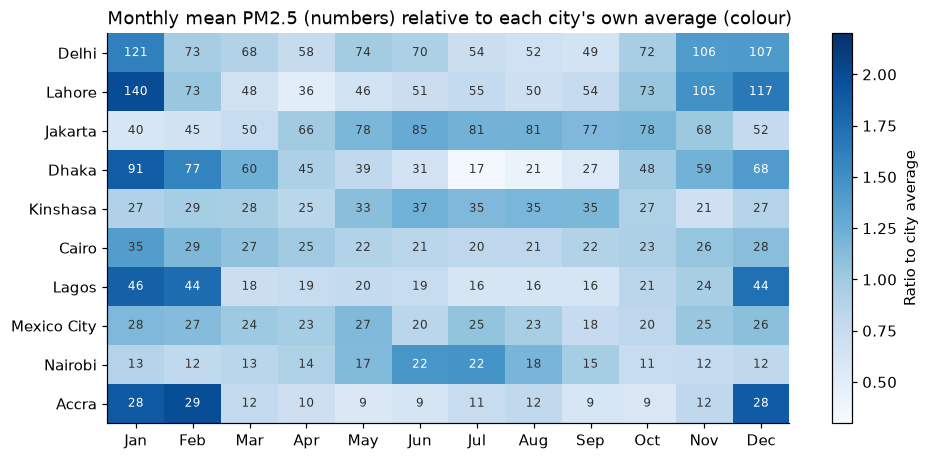

Worst month and its ratio to the best month:
  Delhi        Jan   2.5x
  Lahore       Jan   3.9x
  Jakarta      Jun   2.1x
  Dhaka        Jan   5.3x
  Kinshasa     Jun   1.8x
  Cairo        Jan   1.7x
  Lagos        Jan   3.0x
  Mexico City  Jan   1.5x
  Nairobi      Jul   1.9x
  Accra        Feb   3.4x


In [4]:
data["month"] = data["date"].dt.month
monthly = data.pivot_table(index="city", columns="month", values="pm25", aggfunc="mean").loc[stats.index]
relative = monthly.div(monthly.mean(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 4.6))
image = ax.imshow(relative.values, cmap="Blues", aspect="auto", vmin=0.3, vmax=2.2)
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(relative)), relative.index)
ax.grid(False)
for i in range(relative.shape[0]):
    for j in range(relative.shape[1]):
        ax.text(j, i, f"{monthly.values[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if relative.values[i, j] > 1.4 else "#333")
ax.set_title("Monthly mean PM2.5 (numbers) relative to each city's own average (colour)", loc="left")
fig.colorbar(image, ax=ax, label="Ratio to city average")
plt.show()

peak_month = monthly.idxmax(axis=1)
names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print("Worst month and its ratio to the best month:")
for city in monthly.index:
    print(f"  {city:<12} {names[peak_month[city] - 1]}   {monthly.loc[city].max() / monthly.loc[city].min():.1f}x")

* In **South Asia** (Delhi, Lahore, Dhaka) pollution peaks from November to January. Cold, still air traps emissions near the ground, and crop residue burning adds to them. The monsoon months are far cleaner.
* In **West Africa** (Lagos, Accra) the peak is December to February, when the Harmattan wind carries Saharan dust south.
* South of the equator the calendar flips: **Jakarta, Kinshasa and Nairobi** peak in June and July, which is their dry season.
* Cairo and Mexico City have the flattest profiles, with the worst month about one and a half times the best.

### Weather and pollution

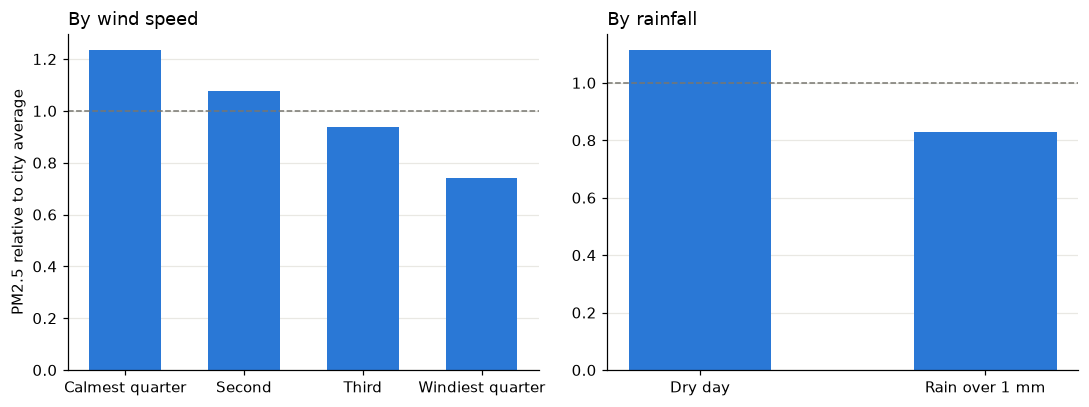

Calmest quarter of days: 1.23 times the city average.  Windiest quarter: 0.74.
Dry days: 1.11.  Rainy days: 0.83.


In [5]:
valid = data.dropna(subset=["pm25", "wind", "rain"]).copy()
valid["wind_band"] = valid.groupby("city")["wind"].transform(lambda s: pd.qcut(s, 4, labels=["Calmest quarter", "Second", "Third", "Windiest quarter"]))
valid["relative_pm"] = valid["pm25"] / valid.groupby("city")["pm25"].transform("mean")
by_wind = valid.groupby("wind_band", observed=True)["relative_pm"].mean()
by_rain = valid.groupby(valid["rain"] > 1)["relative_pm"].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(by_wind.index.astype(str), by_wind.values, color=BLUE, width=0.6)
axes[0].axhline(1, color=GREY, ls="--", lw=1)
axes[0].set_ylabel("PM2.5 relative to city average")
axes[0].set_title("By wind speed", loc="left")
axes[1].bar(["Dry day", "Rain over 1 mm"], by_rain.values, color=BLUE, width=0.5)
axes[1].axhline(1, color=GREY, ls="--", lw=1)
axes[1].set_title("By rainfall", loc="left")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print(f"Calmest quarter of days: {by_wind.iloc[0]:.2f} times the city average.  Windiest quarter: {by_wind.iloc[-1]:.2f}.")
print(f"Dry days: {by_rain.loc[False]:.2f}.  Rainy days: {by_rain.loc[True]:.2f}.")

Wind disperses pollution and rain washes particles out of the air. Both effects are visible within every city after accounting for that city's own average. This is why tomorrow's weather forecast should help predict tomorrow's pollution.

## 4. Forecasting tomorrow

**Target.** Tomorrow's 24-hour mean PM2.5, modelled as the change in its logarithm from today. Working in logs means an error of 10 percent counts the same in a clean city as in a polluted one, so a single model can serve all ten.

**Features**

| Feature | Meaning |
|---|---|
| `l1`, `l2`, `l3` | Log PM2.5 today, yesterday and the day before |
| `m7`, `s7` | Mean and variability over the last seven days |
| `d1` | Change from yesterday to today |
| `temp_today`, `humidity_today`, `wind_today`, `rain_today` | Today's weather |
| `temp_tom`, `humidity_tom`, `wind_tom`, `rain_tom` | Tomorrow's weather |
| `doy_sin`, `doy_cos` | Time of year |
| `dow` | Day of the week tomorrow (traffic and industry follow the week) |
| `city_*` | Which city |

**About tomorrow's weather.** In live use, tomorrow's weather comes from a weather forecast. For training, the recorded weather is used in its place. One-day weather forecasts are accurate, so this is a reasonable stand-in, but it means the test scores below are slightly optimistic compared with real operation.

**Baselines**

* **Persistence**: tomorrow will be the same as today. Air pollution is highly persistent from day to day, so this is a strong baseline.
* **Seven-day average**: tomorrow will equal the average of the last week.

**Validation.** A strict split in time. The model is trained on data up to 31 October 2025 and tested on the following 12 months, which it never sees. Early stopping uses the last six months of the training period.

In [6]:
city_names = list(CITIES)
BASE = ["l1", "l2", "l3", "m7", "s7", "d1", "temp_today", "humidity_today", "wind_today", "rain_today",
        "temp_tom", "humidity_tom", "wind_tom", "rain_tom", "doy_sin", "doy_cos", "dow"]
FEATURES = BASE + [f"city_{i}" for i in range(len(city_names))]

parts = []
for i, city in enumerate(city_names):
    d = data[data["city"] == city].sort_values("date").set_index("date")
    d = d.asfreq("D")
    lp = np.log(d["pm25"].clip(lower=0.5))
    f = pd.DataFrame(index=d.index)
    f["l1"], f["l2"], f["l3"] = lp, lp.shift(1), lp.shift(2)
    f["m7"] = np.log(d["pm25"].rolling(7).mean())
    f["s7"] = lp.rolling(7).std()
    f["d1"] = lp - lp.shift(1)
    f["temp_today"], f["humidity_today"], f["wind_today"] = d["temp"], d["humidity"], d["wind"]
    f["rain_today"] = np.log1p(d["rain"])
    f["temp_tom"], f["humidity_tom"], f["wind_tom"] = d["temp"].shift(-1), d["humidity"].shift(-1), d["wind"].shift(-1)
    f["rain_tom"] = np.log1p(d["rain"].shift(-1))
    target_date = f.index + pd.Timedelta(days=1)
    f["doy_sin"] = np.sin(2 * np.pi * target_date.dayofyear / 365.25)
    f["doy_cos"] = np.cos(2 * np.pi * target_date.dayofyear / 365.25)
    f["dow"] = target_date.dayofweek
    for j in range(len(city_names)):
        f[f"city_{j}"] = int(i == j)
    f["y"] = lp.shift(-1) - lp
    f["pm_today"], f["pm_tomorrow"], f["pm_week"] = d["pm25"], d["pm25"].shift(-1), d["pm25"].rolling(7).mean()
    f["city"], f["target_date"] = city, target_date
    parts.append(f.reset_index())
table = pd.concat(parts, ignore_index=True).dropna(subset=FEATURES + ["y"]).reset_index(drop=True)

TEST_START, VAL_START = pd.Timestamp("2025-11-01"), pd.Timestamp("2025-05-01")
train = table[table["target_date"] < VAL_START]
val = table[(table["target_date"] >= VAL_START) & (table["target_date"] < TEST_START)]
test = table[table["target_date"] >= TEST_START]
print(f"train {len(train):,}   validation {len(val):,}   test {len(test):,} city-days ({test['target_date'].min():%d %b %Y} to {test['target_date'].max():%d %b %Y})")

train 9,930   validation 1,840   test 3,770 city-days (01 Nov 2025 to 12 Nov 2026)


In [7]:
PARAMS = dict(learning_rate=0.03, max_depth=5, min_child_weight=10, subsample=0.8, colsample_bytree=0.8, reg_lambda=3.0, random_state=SEED, n_jobs=4)
probe = xgb.XGBRegressor(n_estimators=1500, early_stopping_rounds=50, **PARAMS).fit(train[FEATURES], train["y"], eval_set=[(val[FEATURES], val["y"])], verbose=False)
n_trees = probe.best_iteration + 1
fit_data = pd.concat([train, val])
model = xgb.XGBRegressor(n_estimators=n_trees, **PARAMS).fit(fit_data[FEATURES], fit_data["y"])
print(f"{n_trees} trees chosen by early stopping, then refitted on training plus validation data")

test = test.assign(
    pred_model=np.exp(test["l1"] + model.predict(test[FEATURES])),
    pred_persistence=test["pm_today"],
    pred_week=test["pm_week"],
)

717 trees chosen by early stopping, then refitted on training plus validation data


## 5. Results on the held-out year

In [8]:
def scores(actual, predicted):
    return {"MAE (µg/m³)": float(np.mean(np.abs(predicted - actual))),
            "Median error (%)": float(np.median(np.abs(predicted / actual - 1)) * 100),
            "R squared": float(r2_score(actual, predicted))}


metrics = pd.DataFrame({
    "Persistence": scores(test["pm_tomorrow"], test["pred_persistence"]),
    "Seven-day average": scores(test["pm_tomorrow"], test["pred_week"]),
    "Gradient boosting": scores(test["pm_tomorrow"], test["pred_model"]),
}).T
improvement = 1 - metrics.loc["Gradient boosting", "MAE (µg/m³)"] / metrics.loc["Persistence", "MAE (µg/m³)"]
print(f"Model error is {improvement:.0%} lower than persistence")
metrics.round(3)

Model error is 17% lower than persistence


,MAE (µg/m³),Median error (%),R squared
Persistence,7.868,15.916,0.869
Seven-day average,9.811,18.962,0.787
Gradient boosting,6.551,13.295,0.910


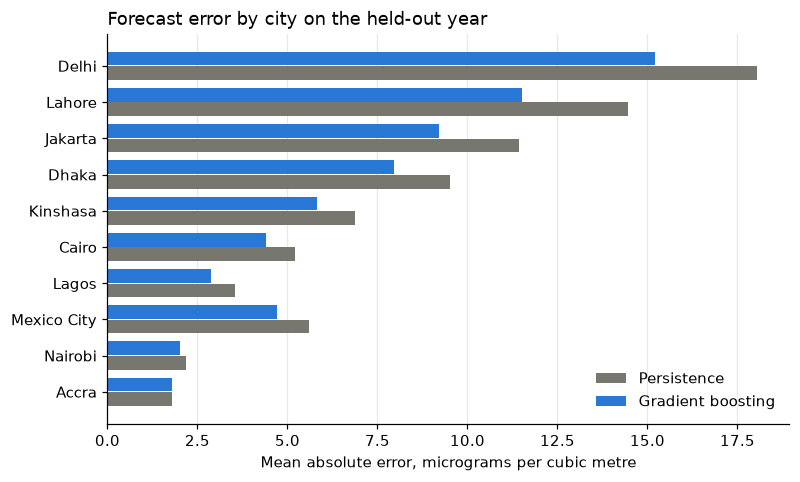

,mean_pm25,persistence_mae,model_mae,improvement
city,,,,
Delhi,88.608,18.043,15.218,0.157
Lahore,74.939,14.464,11.510,0.204
Jakarta,72.459,11.433,9.200,0.195
Dhaka,49.955,9.525,7.958,0.164
Kinshasa,27.970,6.884,5.818,0.155
Cairo,22.971,5.202,4.394,0.155
Lagos,19.914,3.554,2.878,0.190
Mexico City,25.707,5.601,4.713,0.159
Nairobi,12.010,2.169,2.027,0.066


In [9]:
by_city = test.groupby("city").apply(lambda g: pd.Series({
    "mean_pm25": g["pm_tomorrow"].mean(),
    "persistence_mae": np.mean(np.abs(g["pred_persistence"] - g["pm_tomorrow"])),
    "model_mae": np.mean(np.abs(g["pred_model"] - g["pm_tomorrow"])),
})).loc[stats.index]
by_city["improvement"] = 1 - by_city["model_mae"] / by_city["persistence_mae"]

fig, ax = plt.subplots(figsize=(8, 4.6))
positions = np.arange(len(by_city))
ax.barh(positions + 0.2, by_city["persistence_mae"], height=0.38, color=GREY, label="Persistence")
ax.barh(positions - 0.2, by_city["model_mae"], height=0.38, color=BLUE, label="Gradient boosting")
ax.set_yticks(positions, by_city.index)
ax.invert_yaxis()
ax.set_xlabel("Mean absolute error, micrograms per cubic metre")
ax.set_title("Forecast error by city on the held-out year", loc="left")
ax.legend(frameon=False)
ax.grid(axis="y", visible=False)
plt.show()
by_city.round(3)

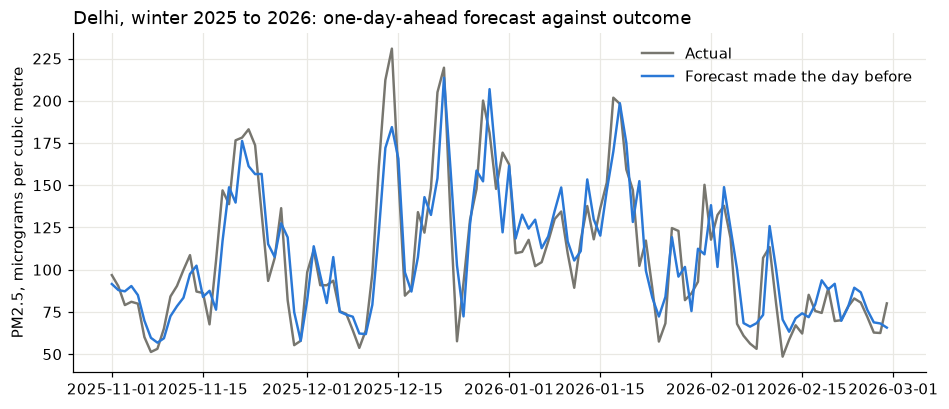

In [10]:
example = test[test["city"] == "Delhi"].set_index("target_date").loc["2025-11-01":"2026-02-28"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(example.index, example["pm_tomorrow"], color=GREY, lw=1.6, label="Actual")
ax.plot(example.index, example["pred_model"], color=BLUE, lw=1.6, label="Forecast made the day before")
ax.set_ylabel("PM2.5, micrograms per cubic metre")
ax.set_title("Delhi, winter 2025 to 2026: one-day-ahead forecast against outcome", loc="left")
ax.legend(frameon=False)
plt.show()

Overall the model's error is 17 percent lower than persistence. It is 15 to 20 percent lower in eight of the ten cities, 7 percent lower in Nairobi, and no better than persistence in Accra, the cleanest city, where day-to-day changes are small and there is little left to explain. The Delhi chart shows what that looks like in practice during the most polluted season: the forecast follows the rises and falls, though it tends to undershoot the most extreme peaks, which is typical of models trained to minimise average error.

## 6. As a warning system

A forecast is most valuable on the days that matter. Define a **high pollution day** for each city as one in the worst quarter of that city's own record in the training period. That makes the definition meaningful everywhere: a bad day in Nairobi is not the same number as a bad day in Lahore.

Two measures matter for a warning system:

* **Recall**: of the high pollution days that happened, what share were warned about the day before?
* **Precision**: of the warnings issued, what share were followed by a high pollution day?

In [11]:
thresholds = fit_data.groupby("city")["pm_today"].quantile(0.75)
test = test.assign(threshold=test["city"].map(thresholds))
actual_high = test["pm_tomorrow"] > test["threshold"]


def alert_scores(predicted):
    warned = predicted > test["threshold"]
    hits = (warned & actual_high).sum()
    return {"Recall": hits / actual_high.sum(), "Precision": hits / warned.sum(), "Warnings issued": int(warned.sum())}


alerts = pd.DataFrame({"Persistence": alert_scores(test["pred_persistence"]), "Gradient boosting": alert_scores(test["pred_model"])}).T
print(f"High pollution days in the test year: {int(actual_high.sum()):,} of {len(test):,} city-days")
alerts.round(3)

High pollution days in the test year: 919 of 3,770 city-days


,Recall,Precision,Warnings issued
Persistence,0.731,0.731,919.0
Gradient boosting,0.742,0.763,894.0


### Uncertainty

The forecast errors on the validation period give an empirical 80 percent interval, which is then checked on the test year.

In [12]:
val_error = np.log(val["pm_tomorrow"]) - (val["l1"] + probe.predict(val[FEATURES]))
low_q, high_q = np.quantile(val_error, [0.1, 0.9])
log_error = np.log(test["pm_tomorrow"]) - np.log(test["pred_model"])
coverage = float(((log_error >= low_q) & (log_error <= high_q)).mean())
print(f"80% interval from validation errors: {np.exp(low_q) - 1:+.0%} to {np.exp(high_q) - 1:+.0%} around the forecast")
print(f"Share of test-year outcomes inside that interval: {coverage:.1%}")

80% interval from validation errors: -24% to +25% around the forecast
Share of test-year outcomes inside that interval: 77.5%


## 7. What the model uses

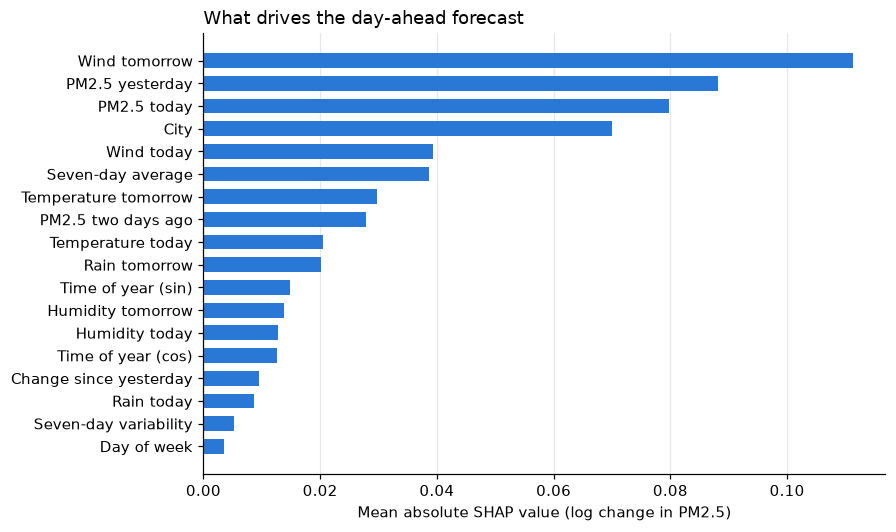

In [13]:
contrib = model.get_booster().predict(xgb.DMatrix(test[FEATURES]), pred_contribs=True)[:, :-1]
importance = pd.Series(np.abs(contrib).mean(axis=0), index=FEATURES)
importance = importance.groupby(lambda name: "city" if name.startswith("city_") else name).sum().sort_values()
LABELS = {"l1": "PM2.5 today", "l2": "PM2.5 yesterday", "l3": "PM2.5 two days ago", "m7": "Seven-day average", "s7": "Seven-day variability",
          "d1": "Change since yesterday", "temp_today": "Temperature today", "humidity_today": "Humidity today", "wind_today": "Wind today",
          "rain_today": "Rain today", "temp_tom": "Temperature tomorrow", "humidity_tom": "Humidity tomorrow", "wind_tom": "Wind tomorrow",
          "rain_tom": "Rain tomorrow", "doy_sin": "Time of year (sin)", "doy_cos": "Time of year (cos)", "dow": "Day of week", "city": "City"}
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh([LABELS[k] for k in importance.index], importance.values, color=BLUE, height=0.65)
ax.set_xlabel("Mean absolute SHAP value (log change in PM2.5)")
ax.set_title("What drives the day-ahead forecast", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

Tomorrow's wind is the single most important input, ahead of the recent pollution levels themselves. Which city it is, today's wind, the weekly average and tomorrow's temperature follow. That is physically sensible: pollution builds up when the air is still and clears when wind arrives, so knowing tomorrow's weather is what lets the model do better than assuming no change.

## 8. Export for the live dashboard

The dashboard fetches the latest PM2.5 and tomorrow's weather forecast from Open-Meteo in the browser, builds the same features and runs the model there. The trees are exported to JSON and re-scored in pure Python to confirm they match XGBoost.

In [14]:
def export_trees(model, columns, sample):
    booster = model.get_booster()
    index = {name: i for i, name in enumerate(columns)}
    trees = []
    for dump in booster.get_dump(dump_format="json"):
        nodes = {}
        stack = [json.loads(dump.replace(": -inf", ": -1e38").replace(": inf", ": 1e38"))]
        while stack:
            node = stack.pop()
            nodes[node["nodeid"]] = node
            stack.extend(node.get("children", []))
        size = max(nodes) + 1
        tree = {"f": [-1] * size, "t": [0] * size, "y": [0] * size, "n": [0] * size, "m": [0] * size, "v": [0] * size}
        for i, node in nodes.items():
            if "leaf" in node:
                tree["v"][i] = round(node["leaf"], 6)
            else:
                tree["f"][i] = index[node["split"]]
                tree["t"][i] = float(np.float32(node["split_condition"]))
                tree["y"][i], tree["n"][i], tree["m"][i] = node["yes"], node["no"], node["missing"]
        trees.append(tree)

    def raw_sum(row):
        total = 0.0
        for tree in trees:
            i = 0
            while tree["f"][i] != -1:
                value = row[tree["f"][i]]
                i = tree["m"][i] if np.isnan(value) else (tree["y"][i] if value < tree["t"][i] else tree["n"][i])
            total += tree["v"][i]
        return total

    values = sample.to_numpy(dtype=np.float32).astype(float)
    sums = np.array([raw_sum(row) for row in values])
    margins = booster.predict(xgb.DMatrix(sample), output_margin=True)
    base = float(np.mean(margins - sums))
    assert np.max(np.abs(sums + base - margins)) < 1e-4, "exported trees do not reproduce the model"
    return {"features": list(columns), "base": round(base, 6), "trees": trees, "objective": "regression"}


exported = export_trees(model, FEATURES, test[FEATURES].sample(500, random_state=SEED))
print("Exported", len(exported["trees"]), "trees. Predictions match XGBoost on 500 test rows.")

Exported 717 trees. Predictions match XGBoost on 500 test rows.


In [15]:
def rounded(values, digits=1):
    return [None if pd.isna(v) else round(float(v), digits) for v in values]


recent = {}
for city in city_names:
    part = test[test["city"] == city].sort_values("target_date").tail(120)
    recent[city] = {"dates": [d.strftime("%Y-%m-%d") for d in part["target_date"]], "actual": rounded(part["pm_tomorrow"]), "forecast": rounded(part["pred_model"])}

last_row = table.sort_values("target_date").groupby("city").tail(1).set_index("city")
check = {city: {"features": [float(v) for v in last_row.loc[city, FEATURES]], "prediction": float(np.exp(last_row.loc[city, "l1"] + model.predict(last_row.loc[[city], FEATURES])[0]))} for city in city_names}

summary = {
    "cities": [{"name": c, "lat": CITIES[c][0], "lon": CITIES[c][1], "country": CITIES[c][2], "threshold": float(thresholds[c])} for c in city_names],
    "period": {"start": START, "end": END, "test_start": TEST_START.strftime("%Y-%m-%d")},
    "city_days": int(len(data)), "hourly_values": int(sum(len(h) for h in hourly_frames.values())),
    "stats": json.loads(stats.reset_index().to_json(orient="records")),
    "monthly": {"cities": list(monthly.index), "values": [rounded(row) for row in monthly.values], "relative": [rounded(row, 2) for row in relative.values]},
    "by_wind": {"labels": [str(k) for k in by_wind.index], "values": rounded(by_wind.values, 3)},
    "by_rain": {"dry": float(by_rain.loc[False]), "rain": float(by_rain.loc[True])},
    "metrics": json.loads(metrics.reset_index().rename(columns={"index": "model"}).to_json(orient="records")),
    "improvement": float(improvement),
    "by_city": json.loads(by_city.reset_index().to_json(orient="records")),
    "alerts": json.loads(alerts.reset_index().rename(columns={"index": "model"}).to_json(orient="records")),
    "high_days": int(actual_high.sum()), "test_days": int(len(test)),
    "interval": {"low": float(low_q), "high": float(high_q), "coverage": coverage},
    "importance": [{"feature": LABELS[k], "value": float(v)} for k, v in importance.sort_values(ascending=False).items()],
    "recent": recent,
    "check": check,
}
(APP / "model.json").write_text(json.dumps(exported, separators=(",", ":")))
(APP / "summary.json").write_text(json.dumps(summary, separators=(",", ":")))
print("model.json", round((APP / "model.json").stat().st_size / 1024), "KB; summary.json", round((APP / "summary.json").stat().st_size / 1024), "KB")

model.json 812 KB; summary.json 38 KB


## 9. Conclusions

* All ten cities exceed the WHO annual guideline for PM2.5. Delhi, Lahore and Jakarta average 13 to 15 times the guideline, and in Delhi and Jakarta four days in ten are above even the WHO's least demanding interim target of 75.
* Pollution is strongly seasonal and the season depends on geography: winter in South Asia, the Harmattan months in West Africa, the dry season south of the equator.
* Calm, dry days are markedly more polluted than windy or wet ones in every city, which is what makes a weather-informed forecast possible.
* A single gradient boosted model forecasts next-day PM2.5 with 17 percent lower error than assuming tomorrow equals today, on a full year it never saw. The gain is 15 to 20 percent in the most polluted cities and negligible in the cleanest.
* As a warning system for each city's worst quarter of days, the model is slightly better than persistence on both recall and precision. Most of the skill in warning comes from pollution episodes lasting several days, which persistence already captures. The model's advantage is in the size of the forecast error, not in the yes or no call.
* An empirical 80 percent interval of roughly plus or minus 25 percent covered 77.5 percent of outcomes in the test year, a little under its nominal level.

**Limitations**

* The PM2.5 data is a satellite-constrained model analysis on a 40 km grid, not ground measurements. It understates roadside peaks and can be biased where observations are sparse. Validating against ground monitors (for example from OpenAQ or embassy monitors) is the most important next step.
* Tomorrow's weather is taken from recorded weather in training. Live forecasts use a weather forecast, which adds some error.
* The model undershoots the most extreme days. A warning system that must not miss those needs a model trained with a loss that weights them more heavily.
* Four years of data is short for learning rare events.

**Next steps.** Calibrate against ground monitors, add fire and dust indicators from satellite products, extend the horizon to three days, and estimate the health burden of days above the guideline.